# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [1]:
import os
import numpy as np
import pandas as pd

# файл лежит в папке data рядом с ноутбуком
# если его нет, берем тот же csv из репозитория intel oneAPI-samples
filepath = os.path.join('data', 'Orange_Telecom_Churn_Data.csv')
if not os.path.exists(filepath):
    filepath = ('https://raw.githubusercontent.com/oneapi-src/oneAPI-samples/master/'
                'Training/Introduction_to_Machine_Learning/data/Orange_Telecom_Churn_Data.csv')

df = pd.read_csv(filepath)
print(df.shape)
df.head()

(5000, 21)


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [2]:
# категориальные колонки: текст, bool и area_code (это код региона, хоть и записан числом)
cat_cols = df.select_dtypes(exclude='number').columns.tolist() + ['area_code']
removed = ['state', 'area_code', 'phone_number']

card = pd.DataFrame({
    'тип': df[cat_cols].dtypes.astype(str),
    'уникальных значений': df[cat_cols].nunique(),
    'доля уникальных': (df[cat_cols].nunique() / len(df)).round(4),
    'статус': ['удалена' if c in removed else 'осталась' for c in cat_cols],
}).sort_values('уникальных значений', ascending=False)
card

,тип,уникальных значений,доля уникальных,статус
phone_number,str,5000,1.0000,удалена
state,str,51,0.0102,удалена
area_code,int64,3,0.0006,удалена
intl_plan,str,2,0.0004,осталась
voice_mail_plan,str,2,0.0004,осталась
churned,bool,2,0.0004,осталась


In [3]:
from sklearn.preprocessing import OneHotEncoder

# сколько колонок даст one-hot для каждого категориального признака (churned - это цель, ее не берем)
features_cat = [c for c in cat_cols if c != 'churned']
ohe = OneHotEncoder().fit(df[features_cat])
for col, cats in zip(features_cat, ohe.categories_):
    print(f'{col:>16}: {len(cats)} колонок')

phone = OneHotEncoder().fit_transform(df[['phone_number']])
cells = phone.shape[0] * phone.shape[1]
print('\nматрица one-hot для phone_number:', phone.shape)
print(f'единиц в ней {phone.nnz} из {cells}, то есть {phone.nnz / cells:.2%} ячеек')
print('в обычном (dense) виде float64 она весит', round(cells * 8 / 1024**2), 'МБ')

           state: 51 колонок
    phone_number: 5000 колонок
       intl_plan: 2 колонок
 voice_mail_plan: 2 колонок
       area_code: 3 колонок

матрица one-hot для phone_number: (5000, 5000)
единиц в ней 5000 из 25000000, то есть 0.02% ячеек
в обычном (dense) виде float64 она весит 191 МБ


In [4]:
from sklearn.preprocessing import MinMaxScaler

# числовые признаки в [0, 1], как в ноутбуке
num_cols = df.select_dtypes(include='number').columns.drop('area_code')
X_num = MinMaxScaler().fit_transform(df[num_cols])

# 5000 случайных пар разных клиентов
rng = np.random.default_rng(42)
pair_i, pair_j = rng.integers(0, len(df), size=(2, 5000))
keep = pair_i != pair_j
pair_i, pair_j = pair_i[keep], pair_j[keep]

# вклад в квадрат евклидова расстояния d^2
d2_num = ((X_num[pair_i] - X_num[pair_j]) ** 2).sum(axis=1)
d2_state = 2 * (df['state'].values[pair_i] != df['state'].values[pair_j])
d2_phone = 2 * (df['phone_number'].values[pair_i] != df['phone_number'].values[pair_j])

print(f'все {len(num_cols)} числовых признаков: медиана d^2 = {np.median(d2_num):.3f}, '
      f'у 90% пар d^2 < {np.quantile(d2_num, 0.9):.3f}')
print(f'one-hot state: d^2 = 2 у {np.mean(d2_state == 2):.1%} пар, у остальных 0')
print(f'one-hot phone_number: d^2 = 2 у {np.mean(d2_phone == 2):.1%} пар')

все 15 числовых признаков: медиана d^2 = 0.613, у 90% пар d^2 < 1.115
one-hot state: d^2 = 2 у 98.1% пар, у остальных 0
one-hot phone_number: d^2 = 2 у 100.0% пар


In [5]:
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split

# дальше как в ноутбуке: удаляем 3 колонки, yes/no и True/False переводим в 0/1
data = df.drop(columns=removed)
lb = LabelBinarizer()
for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    data[col] = lb.fit_transform(data[col]).ravel()

X = data.drop(columns='churned')
y = data['churned']

# одно разбиение train/test на все задания (test 25%, доля ушедших одинаковая)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('train:', X_train.shape, ' test:', X_test.shape)

train: (3750, 17)  test: (1250, 17)


In [6]:
import scipy.sparse as sp
from sklearn.neighbors import KNeighborsClassifier

# проверяем на деле: что будет с knn, если вернуть state и phone_number через one-hot
def knn_test_accuracy(extra_cols=()):
    sc = MinMaxScaler().fit(X_train)
    parts_train = [sp.csr_matrix(sc.transform(X_train))]
    parts_test = [sp.csr_matrix(sc.transform(X_test))]
    for col in extra_cols:
        # one-hot колонки и так 0/1, их не скейлим. неизвестный в train номер -> все нули
        enc = OneHotEncoder(handle_unknown='ignore').fit(df.loc[X_train.index, [col]])
        parts_train.append(enc.transform(df.loc[X_train.index, [col]]))
        parts_test.append(enc.transform(df.loc[X_test.index, [col]]))
    A_train, A_test = sp.hstack(parts_train).tocsr(), sp.hstack(parts_test).tocsr()
    knn = KNeighborsClassifier(n_neighbors=5).fit(A_train, y_train)
    return A_train.shape[1], knn.score(A_test, y_test)

for extra in [(), ('state',), ('phone_number',), ('state', 'phone_number')]:
    n_feat, acc = knn_test_accuracy(extra)
    name = ' + '.join(('17 признаков',) + extra)
    print(f'{name:>40}: {n_feat:>5} колонок, точность на test {acc:.4f}')

                            17 признаков:    17 колонок, точность на test 0.8944


                    17 признаков + state:    68 колонок, точность на test 0.8528
             17 признаков + phone_number:  3767 колонок, точность на test 0.8944


     17 признаков + state + phone_number:  3818 колонок, точность на test 0.8528


**Ответ.**

Из удаленных колонок `phone_number` своя у каждого клиента (5000 значений на 5000 строк), у `state` 51 значение, у `area_code` всего 3. `area_code` записан числом, но по смыслу это код зоны, поэтому считаю его категориальным. У оставшихся `intl_plan`, `voice_mail_plan` и `churned` по 2 значения: LabelBinarizer делает из каждой одну колонку 0/1, тут проблем нет.

Почему one-hot для `phone_number` ломает KNN:

1. **Память.** One-hot превращает колонку с n разными значениями в n бинарных колонок. Для телефона это матрица 5000 x 5000 = 25 млн ячеек, и единиц в ней всего 5000 (0.02%). В обычном виде это 191 МБ ради одного признака, хотя всего признаков было 17. Каждый новый клиент приносит новый номер, то есть еще одну колонку.
2. **Расстояние.** У каждого клиента в этих колонках ровно одна единица, и у всех на своем месте. Значит, для любых двух разных клиентов телефонная часть дает в квадрат евклидова расстояния $(1-0)^2 + (0-1)^2 = 2$, одно и то же число для любой пары. Информации о похожести там нет, просто +2 ко всем расстояниям и 5000 лишних измерений, в которых KD-Tree и Ball-Tree уже не помогают и остается полный перебор. У клиента из test номера нет в train, поэтому все 5000 колонок у него нулевые, и к расстоянию до каждого клиента из train добавляется ровно 1. Поэтому в эксперименте точность с телефоном и без него одинаковая (0.8944): порядок соседей не поменялся, а таблица стала примерно в 220 раз шире.
3. **Переобучение.** Номер телефона по сути id клиента. Значение, которое встречается один раз, нельзя обобщить, его можно только запомнить. На train такая колонка "узнает" каждую точку, а на новых данных она бесполезна. Для KNN это особенно плохо: модель и так хранит всю выборку целиком.

С `state` (51 значение) вред видно прямо в цифрах. Если штаты разные, one-hot добавляет к $d^2$ ровно 2, а так у 98% пар. При этом все 15 числовых признаков после MinMaxScaler вместе дают $d^2$ около 0.6 (медиана, у 90% пар меньше 1.1). Получается, что штат весит больше всех остальных признаков вместе, и соседями становятся клиенты из того же штата, а не с похожим поведением. Отток от штата почти не зависит, то есть модель подстраивается под шум, и точность на test падает с 0.894 до 0.853.

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [7]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

two = ['account_length', 'total_day_charge']
print(df[two].describe().loc[['min', 'max', 'std']].round(2), '\n')

# три реальных клиента: у b почти такой же счет за день, как у a, но стаж другой,
# у c почти такой же стаж, как у a, но счет за день сильно другой
a = 0
b = df.index[((df['total_day_charge'] - df.loc[a, 'total_day_charge']).abs() < 0.5)
             & (df['account_length'] - df.loc[a, 'account_length']).abs().between(50, 80)][0]
c = df.index[((df['account_length'] - df.loc[a, 'account_length']).abs() <= 2)
             & ((df['total_day_charge'] - df.loc[a, 'total_day_charge']).abs() > 25)][0]
trio = df.loc[[a, b, c], two]
trio.index = ['a', 'b', 'c']
trio

     account_length  total_day_charge
min            1.00              0.00
max          243.00             59.76
std           39.69              9.16 



,account_length,total_day_charge
a,128,45.07
b,60,45.20
c,126,9.89


In [8]:
def show_distances(M, title):
    M = np.asarray(M, dtype=float)
    d_ab, d_ac = np.linalg.norm(M[0] - M[1]), np.linalg.norm(M[0] - M[2])
    closest = 'b' if d_ab < d_ac else 'c'
    print(f'{title:>15}: d(a, b) = {d_ab:.3f}, d(a, c) = {d_ac:.3f} -> ближе к a клиент {closest}')

mm = MinMaxScaler().fit(df[two])
show_distances(trio, 'без скейлинга')
show_distances(mm.transform(trio), 'MinMaxScaler')

# какая доля квадрата расстояния в среднем приходится на каждый признак (по тем же случайным парам)
def feature_share(M):
    M = np.asarray(M, dtype=float)
    diff2 = ((M[pair_i] - M[pair_j]) ** 2).mean(axis=0)
    return diff2 / diff2.sum()

share = pd.DataFrame({
    'без скейлинга': feature_share(df[two]),
    'MinMaxScaler': feature_share(mm.transform(df[two])),
    'StandardScaler': feature_share(StandardScaler().fit_transform(df[two])),
}, index=two)
print('\nвклад признака в d^2, %')
(share * 100).round(1)

  без скейлинга: d(a, b) = 68.000, d(a, c) = 35.237 -> ближе к a клиент c
   MinMaxScaler: d(a, b) = 0.281, d(a, c) = 0.589 -> ближе к a клиент b

вклад признака в d^2, %


,без скейлинга,MinMaxScaler,StandardScaler
account_length,94.8,52.4,49.0
total_day_charge,5.2,47.6,51.0


In [9]:
# выброс: у одного клиента стаж записали с лишним нулем (2430 вместо 243)
acc = df[['account_length']].astype(float)
acc_out = acc.copy()
acc_out.loc[acc_out['account_length'].idxmax(), 'account_length'] *= 10
normal = (acc_out['account_length'] < 1000).values   # все, кроме выброса

rows = []
for name, scaler in [('MinMaxScaler', MinMaxScaler()), ('StandardScaler', StandardScaler()),
                     ('RobustScaler', RobustScaler())]:
    clean = scaler.fit_transform(acc).ravel()
    dirty = scaler.fit_transform(acc_out).ravel()
    rows.append({'скейлер': name,
                 'std обычных клиентов (без выброса)': clean.std(),
                 'std обычных клиентов (с выбросом)': dirty[normal].std(),
                 'диапазон обычных (с выбросом)': f'{dirty[normal].min():.2f} .. {dirty[normal].max():.2f}',
                 'значение у выброса': dirty[~normal][0]})
pd.DataFrame(rows).round(3)

,скейлер,std обычных клиентов (без выброса),std обычных клиентов (с выбросом),диапазон обычных (с выбросом),значение у выброса
0,MinMaxScaler,0.164,0.016,0.00 .. 0.10,1.000
1,StandardScaler,1.000,0.769,-1.93 .. 2.66,45.192
2,RobustScaler,0.735,0.734,-1.83 .. 2.56,43.148


**Ответ.**

Без скейлинга евклидово расстояние считает разницу в исходных единицах: один день стажа весит столько же, сколько один доллар дневного счета. Стаж разбросан гораздо сильнее (std 39.7 против 9.2), поэтому в среднем 94.8% квадрата расстояния дает `account_length`, а `total_day_charge` почти ни на что не влияет (5.2%).

На трех клиентах это хорошо видно. У b такой же дневной счет, как у a (45.20 и 45.07), но стаж на 68 дней меньше. У c почти тот же стаж, но счет меньше на 35 долларов, а это больше половины всего диапазона счета. Без скейлинга ближе к a оказывается c (35.2 против 68.0), хотя по деньгам это совсем другой клиент. После MinMaxScaler оба признака в [0, 1]: 68 дней это 0.28 диапазона, 35 долларов 0.59, и ближе становится b. Вклад признаков выравнивается примерно до 52/48.

**Выбросы.** MinMaxScaler считает по min и max, и выброс сам становится max. В примере один стаж 2430 (лишний ноль) сжимает всех обычных клиентов в [0, 0.10], их разброс падает в 10 раз (0.164 -> 0.016). Признак почти пропадает из расстояния, хотя испорчено одно значение из 5000.

StandardScaler использует среднее и std. Выброс их тоже сдвигает, но не так сильно: разброс обычных клиентов падает с 1 до 0.77, и они остаются примерно в -1.9 .. 2.7. Зато диапазон ничем не ограничен, и сам выброс получает значение 45. Для KNN он очень далеко от всех остальных, а если все же попадет в соседи, то по этому признаку забьет все остальные. Получается, что с выбросами StandardScaler лучше MinMaxScaler, но тоже не идеален. Надежнее RobustScaler (медиана и межквартильный размах): ему выброс вообще не мешает, разброс обычных клиентов 0.735 и с ним, и без него. Ну или найти и убрать выбросы до масштабирования.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [10]:
import timeit
import numpy as np
from sklearnex import patch_sklearn, unpatch_sklearn

# синтетические данные, X_syn и y_syn - чтобы не затереть X и y из churn
rng = np.random.default_rng(0)
X_syn = rng.random((100000, 10))
y_syn = rng.integers(0, 2, 100000)
X_query = X_syn[:5000]   # на этих точках меряем predict

def bench(n_repeat=3):
    # импорт внутри функции, чтобы после патча взять уже версию intel
    from sklearn.neighbors import KNeighborsClassifier
    knn = KNeighborsClassifier(n_neighbors=5)
    t_fit = min(timeit.repeat(lambda: knn.fit(X_syn, y_syn), number=1, repeat=n_repeat))
    t_pred = min(timeit.repeat(lambda: knn.predict(X_query), number=1, repeat=n_repeat))
    return {'модуль класса': KNeighborsClassifier.__module__, 'fit, с': t_fit, 'predict 5000 точек, с': t_pred}

unpatch_sklearn()   # обычный scikit-learn
stock = bench()
patch_sklearn()     # scikit-learn + intel extension
intel = bench()

times = pd.DataFrame([stock, intel], index=['без патча', 'с патчем'])
print(times.round(4).to_string())
print(f"\nускорение: fit в {stock['fit, с'] / intel['fit, с']:.1f} раз, "
      f"predict в {stock['predict 5000 точек, с'] / intel['predict 5000 точек, с']:.1f} раз")

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


                                    модуль класса  fit, с  predict 5000 точек, с
без патча       sklearn.neighbors._classification  0.0961                 0.5535
с патчем   sklearnex.neighbors.knn_classification  0.0214                 0.0241

ускорение: fit в 4.5 раз, predict в 23.0 раз


In [11]:
# какие векторные инструкции есть у процессора (linux)
if os.path.exists('/proc/cpuinfo'):
    cpuinfo = open('/proc/cpuinfo').read()
    model = [line.split(':')[1].strip() for line in cpuinfo.splitlines() if line.startswith('model name')][0]
    print('процессор:', model)
    for flag in ['avx2', 'avx512f']:
        print(f'{flag}:', 'есть' if f' {flag} ' in cpuinfo else 'нет')

# дальше во всем ноутбуке используем ускоренные классы
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

процессор: AMD Ryzen 7 5825U with Radeon Graphics
avx2: есть
avx512f: нет


**Ответ.**

`patch_sklearn()` подменяет классы scikit-learn на версии из Intel Extension. Это видно по модулю класса: после патча `KNeighborsClassifier` берется уже из `sklearnex.neighbors`. Код при этом не меняется, а сами вычисления уходят в библиотеку oneDAL (написана на C++). Ускорение берется из нескольких мест:

- **Все ядра.** Обычный KNN в sklearn ищет соседей в одном потоке, если не задать `n_jobs`. oneDAL сам распределяет поиск по всем ядрам через oneTBB (у меня их 16 потоков).
- **Векторные инструкции (SIMD).** Расстояние - это много одинаковых операций: разность, квадрат, сумма. AVX2 обрабатывает 4 числа float64 за одну инструкцию, AVX-512 обрабатывает 8. oneDAL сам определяет, что умеет процессор, и выбирает нужную версию кода.
- **Структуры данных.** oneDAL выбирает между KD-Tree и полным перебором (brute force). KD-Tree хранится компактно и обходится без накладных расходов Python/Cython. Полный перебор считается как умножение матриц через $\|a-b\|^2 = \|a\|^2 + \|b\|^2 - 2ab$ блоками, которые помещаются в кэш (тот же прием в упражнении 6 в CustomKNN).

В моем замере на 100 000 точках fit с патчем быстрее примерно в 4 раза, а predict (5000 запросов) в 20-30 раз. Точные числа прыгают от запуска к запуску, смотри таблицу выше. Fit у KNN быстрый в любом случае: модель просто запоминает данные и строит индекс. Главное ускорение приходится на predict, где и идет поиск соседей.

Важно: у моего ноутбука процессор AMD Ryzen 7 5825U, AVX2 есть, а **AVX-512 нет**. Поэтому oneDAL работает тут на AVX2, и все ускорение получено без AVX-512. На Intel Xeon с AVX-512 разница была бы еще больше. И еще: в упражнении 5 оказалось, что ускоренная версия с `weights='distance'` иногда отвечает не так, как обычный sklearn, так что результаты патча все равно стоит проверять.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [12]:
def minkowski_distance(x, y, p):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if p < 1:
        raise ValueError('при p < 1 это уже не метрика: ломается неравенство треугольника')
    if np.isinf(p):
        # предел при p -> бесконечность: расстояние чебышева, самая большая разница по координате
        return np.max(np.abs(x - y), axis=-1)
    # axis=-1, чтобы функция работала и для целых массивов точек
    return np.sum(np.abs(x - y) ** p, axis=-1) ** (1 / p)

# расстояние между (0, 0) и (3, 4) для разных p
for p in [1, 1.5, 2, 3, 5, 10, 50, np.inf]:
    print(f'p = {p:>4}: {minkowski_distance([0, 0], [3, 4], p):.4f}')

p =    1: 7.0000
p =  1.5: 5.5843
p =    2: 5.0000
p =    3: 4.4979
p =    5: 4.1740
p =   10: 4.0220
p =   50: 4.0000
p =  inf: 4.0000


In [13]:
from sklearn.metrics import DistanceMetric

# сверяем с sklearn на 200 клиентах из churn (все пары сразу через broadcasting)
A = MinMaxScaler().fit_transform(X)[:200]
for p in [1, 2, 3, np.inf]:
    if np.isinf(p):
        metric = DistanceMetric.get_metric('chebyshev')
    else:
        metric = DistanceMetric.get_metric('minkowski', p=p)
    ours = minkowski_distance(A[:, None, :], A[None, :, :], p)
    print(f'p = {p}: совпадает с sklearn - {np.allclose(ours, metric.pairwise(A))}')

p = 1: совпадает с sklearn - True
p = 2: совпадает с sklearn - True
p = 3: совпадает с sklearn - True
p = inf: совпадает с sklearn - True


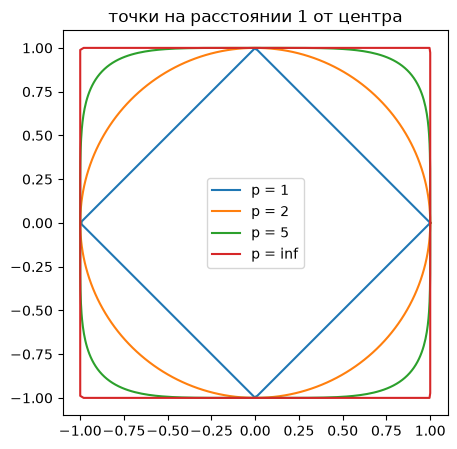

In [14]:
import matplotlib.pyplot as plt

# "окружности" радиуса 1 в разных метриках, считаем своей функцией
angles = np.linspace(0, 2 * np.pi, 400)
dirs = np.c_[np.cos(angles), np.sin(angles)]
fig, ax = plt.subplots(figsize=(5, 5))
for p in [1, 2, 5, np.inf]:
    pts = dirs / minkowski_distance(dirs, np.zeros(2), p)[:, None]
    ax.plot(pts[:, 0], pts[:, 1], label=f'p = {p}')
ax.set_aspect('equal')
ax.set_title('точки на расстоянии 1 от центра')
ax.legend()
plt.show()

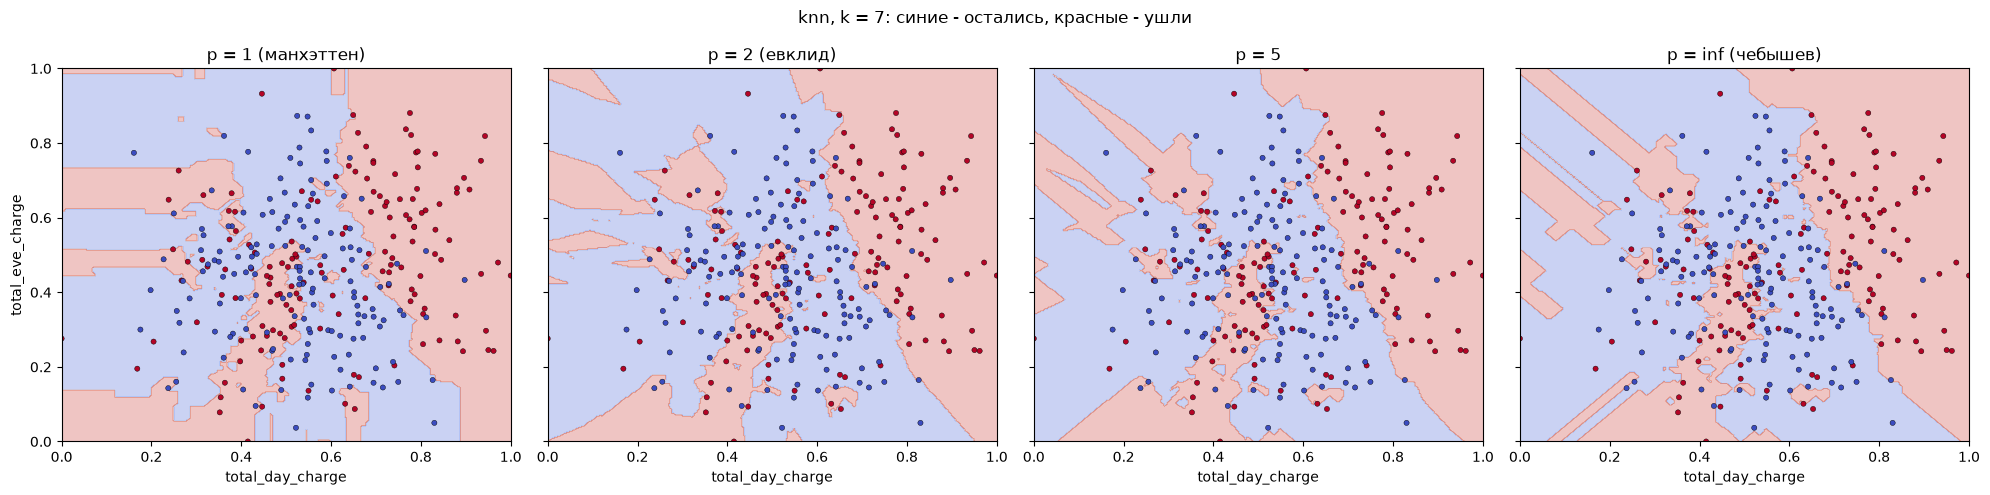

   p = 1 (манхэттен): отличается от p = 2 на 10.0% площади
      p = 2 (евклид): отличается от p = 2 на 0.0% площади
               p = 5: отличается от p = 2 на 7.5% площади
   p = inf (чебышев): отличается от p = 2 на 9.5% площади


In [15]:
# двумерный бинарный набор: дневной и вечерний счет, цель churned
# берем по 150 ушедших и оставшихся, чтобы оба класса было видно
feat2 = ['total_day_charge', 'total_eve_charge']
sample = pd.concat([data[data['churned'] == 1].sample(150, random_state=1),
                    data[data['churned'] == 0].sample(150, random_state=1)])
X2 = MinMaxScaler().fit_transform(sample[feat2])
y2 = sample['churned'].to_numpy()

xx, yy = np.meshgrid(np.linspace(0, 1, 300), np.linspace(0, 1, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]

settings = [('p = 1 (манхэттен)', dict(p=1)), ('p = 2 (евклид)', dict(p=2)),
            ('p = 5', dict(p=5)), ('p = inf (чебышев)', dict(metric='chebyshev'))]
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
boundary = {}
for ax, (title, params) in zip(axes, settings):
    knn = KNeighborsClassifier(n_neighbors=7, **params).fit(X2, y2)
    boundary[title] = knn.predict(grid_points)
    ax.contourf(xx, yy, boundary[title].reshape(xx.shape), alpha=0.3, cmap='coolwarm')
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='coolwarm', s=14, edgecolor='k', linewidth=0.3)
    ax.set_title(title)
    ax.set_xlabel(feat2[0])
axes[0].set_ylabel(feat2[1])
plt.suptitle('knn, k = 7: синие - остались, красные - ушли')
plt.tight_layout()
plt.show()

# на какой доле площади ответ отличается от евклидова
for title, Z in boundary.items():
    print(f'{title:>20}: отличается от p = 2 на {np.mean(Z != boundary["p = 2 (евклид)"]):.1%} площади')

**Ответ.**

Функция совпадает с `DistanceMetric` из sklearn для p = 1, 2, 3 и бесконечности. Для точек (0, 0) и (3, 4) видно, как расстояние зависит от p: при p = 1 это 3 + 4 = 7, при p = 2 обычные 5, а дальше расстояние уменьшается и стремится к самой большой разнице по координате, то есть к 4 (расстояние Чебышева). При p = 10 уже 4.02, при p = 50 ровно 4.0000. Получается, чем больше p, тем сильнее расстояние определяется одной самой большой разницей: при p = 1 все разницы просто складываются, при p = 2 большие разницы усиливаются квадратом, а при $p \to \infty$ остается только максимальная.

От p меняется форма "окружности" (это точки на расстоянии 1): при p = 1 ромб, при p = 2 круг, при p = 5 скругленный квадрат, при p = inf квадрат. KNN берет k соседей внутри такой фигуры вокруг точки, поэтому метрика задает форму окрестности.

На графиках границ это видно:
- в центре, где точек много, граница почти одинаковая при всех p, ее определяют сами данные (ушедшие клиенты справа, где большой дневной счет);
- при p = 1 границы тянутся горизонтально и вертикально, ступеньками вдоль осей;
- при p = inf появляются линии под 45 градусов: там расстояние считается только по одной координате, где разница больше, и вторая перестает влиять;
- p = 5 выглядит как что-то среднее между евклидом и Чебышевым.

По площади ответы отличаются от евклидова на 7.5-10%, и в основном на краях, где точек мало. Выбор p - это такой же гиперпараметр, как k, его подбирают на кросс-валидации (так и сделано в упражнении 12).

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [16]:
# как в ноутбуке: скейлим все данные, учим и проверяем на одних и тех же строках
X_all = MinMaxScaler().fit_transform(X)
print('одинаковых строк в данных:', X.duplicated().sum())

configs = [dict(n_neighbors=1), dict(n_neighbors=3), dict(n_neighbors=3, weights='distance'),
           dict(n_neighbors=5, weights='distance')]
for params in configs:
    knn = KNeighborsClassifier(**params).fit(X_all, y)
    print(f'{str(params):>40}: точность на обучающих данных {knn.score(X_all, y):.4f}')

одинаковых строк в данных: 0
                      {'n_neighbors': 1}: точность на обучающих данных 1.0000
                      {'n_neighbors': 3}: точность на обучающих данных 0.9422
{'n_neighbors': 3, 'weights': 'distance'}: точность на обучающих данных 0.9732
{'n_neighbors': 5, 'weights': 'distance'}: точность на обучающих данных 0.9732


In [17]:
# соседи первых 5 клиентов: первый сосед каждого - он сам, на расстоянии 0
knn3 = KNeighborsClassifier(n_neighbors=3).fit(X_all, y)
dist, ind = knn3.kneighbors(X_all[:5])
pd.DataFrame({'клиент': range(5), 'индексы соседей': list(ind), 'расстояния': list(dist.round(3))})

,клиент,индексы соседей,расстояния
0,0,"[0, 3469, 4553]","[0.0, 0.238, 0.265]"
1,1,"[1, 1852, 3827]","[0.0, 0.201, 0.254]"
2,2,"[2, 1806, 3653]","[0.0, 0.195, 0.246]"
3,3,"[3, 3872, 2396]","[0.0, 0.537, 0.56]"
4,4,"[4, 269, 465]","[0.0, 0.314, 0.316]"


In [18]:
from importlib.metadata import version

# по теории weights='distance' тоже должен дать 1.0: у самой точки d = 0, ее вес 1/d бесконечный.
# смотрим, на каких клиентах ускоренная версия ошиблась
y_np = y.to_numpy()
knn_d = KNeighborsClassifier(n_neighbors=3, weights='distance').fit(X_all, y)
pred_d = knn_d.predict(X_all)
wrong = np.where(pred_d != y_np)[0]
print(f"scikit-learn-intelex {version('scikit-learn-intelex')}: ошибок {len(wrong)}, настоящий класс у них {np.unique(y_np[wrong])}")
dist, ind = knn_d.kneighbors(X_all[wrong[:3]])
print('расстояния до 3 соседей:\n', dist.round(3))
print('метки соседей:\n', y_np[ind])
print('predict_proba:\n', knn_d.predict_proba(X_all[wrong[:3]]))
print('predict:', pred_d[wrong[:3]])

scikit-learn-intelex 2026.1.0: ошибок 134, настоящий класс у них [1]
расстояния до 3 соседей:
 [[0.    0.452 0.515]
 [0.    0.28  0.313]
 [0.    0.742 0.785]]
метки соседей:
 [[1 0 1]
 [1 1 0]
 [1 1 0]]
predict_proba:
 [[0. 1.]
 [0. 1.]
 [0. 1.]]
predict: [0 0 0]


In [19]:
# то же самое в обычном scikit-learn: на секунду снимаем патч и забираем оригинальный класс
unpatch_sklearn()
from sklearn.neighbors import KNeighborsClassifier as StockKNN
patch_sklearn()
print('StockKNN из модуля', StockKNN.__module__)

for params in configs:
    knn = StockKNN(**params).fit(X_all, y)
    print(f'{str(params):>40}: обычный sklearn, точность на обучающих данных {knn.score(X_all, y):.4f}')

StockKNN из модуля sklearn.neighbors._classification


                      {'n_neighbors': 1}: обычный sklearn, точность на обучающих данных 1.0000


                      {'n_neighbors': 3}: обычный sklearn, точность на обучающих данных 0.9422
{'n_neighbors': 3, 'weights': 'distance'}: обычный sklearn, точность на обучающих данных 1.0000
{'n_neighbors': 5, 'weights': 'distance'}: обычный sklearn, точность на обучающих данных 1.0000


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [20]:
# честная проверка: скейлер и модель учим только на train, считаем точность на train и на test
# (обычный sklearn, чтобы weights='distance' на train считался правильно)
sc = MinMaxScaler().fit(X_train)
X_train_s, X_test_s = sc.transform(X_train), sc.transform(X_test)

rows = []
for params in configs:
    knn = StockKNN(**params).fit(X_train_s, y_train)
    rows.append({'параметры': str(params),
                 'точность на train': knn.score(X_train_s, y_train),
                 'точность на test': knn.score(X_test_s, y_test)})
pd.DataFrame(rows).round(4)

,параметры,точность на train,точность на test
0,{'n_neighbors': 1},1.0000,0.8736
1,{'n_neighbors': 3},0.9437,0.8920
2,"{'n_neighbors': 3, 'weights': 'distance'}",1.0000,0.8920
3,"{'n_neighbors': 5, 'weights': 'distance'}",1.0000,0.8936


**Ответ.**

С K = 1 на тех же данных, на которых учились, точность ровно 1.0. KNN ничего не "учит": fit просто сохраняет всю выборку, то есть модель и есть данные. Если спросить модель про точку $x_i$, которая уже лежит в выборке, ее ближайший сосед - она сама, на расстоянии 0 (в таблице у каждого клиента первый сосед имеет его же индекс и расстояние 0.0). Одинаковых строк в данных нет, поэтому сосед на расстоянии 0 у каждой точки один, и его метка - правильный ответ. Модель не предсказывает, а вспоминает. Это и есть запоминание, крайняя форма переобучения: ошибка на train 0, но это ничего не говорит про новых клиентов.

С K = 3 и равными весами точка сама себе дает только 1 голос из 3, поэтому уже не 100%, а 0.9422: ошибка бывает, когда оба других соседа из другого класса.

С `weights='distance'` вес соседа $1/d$, а у самой точки $d = 0$, вес бесконечный. sklearn в этом случае отдает голос только точкам с расстоянием 0, и ответ опять равен своей метке при любом K. Обычный sklearn так и показывает 1.0 для K = 3 и K = 5.

А вот с патчем Intel получилось 0.9732. Все 134 ошибки на ушедших клиентах (класс 1): `predict_proba` у них честно говорит "класс 1 с вероятностью 1.0", а `predict` возвращает 0. Похоже на баг в sklearnex именно для случая бесконечного веса (видимо, inf/inf дает nan и голосование ломается). Поэтому там, где нужен `weights='distance'` и могут быть расстояния 0 (упражнения 5, 9, 12), беру обычный sklearn.

Честная проверка все расставляет по местам: при K = 1 на train 1.0, а на test всего 0.874, это худший вариант из четырех. У `distance` на train тоже 1.0, а на test около 0.89. Точность на обучающей выборке для KNN вообще ничего не значит, поэтому нужны отдельный test или кросс-валидация (упражнение 7).

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [21]:
class CustomKNN:
    def __init__(self, batch_size=500):
        # считаем расстояния кусками по batch_size точек, чтобы не забить память
        self.batch_size = batch_size

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        # метки переводим в 0..n_classes-1, так проще считать голоса
        self.classes_, self.y_train = np.unique(np.asarray(y), return_inverse=True)
        self.train_sq = (self.X_train ** 2).sum(axis=1)
        return self

    def _distances(self, X_batch):
        # ||a - b||^2 = ||a||^2 + ||b||^2 - 2ab, вся матрица одним умножением матриц
        d2 = (X_batch ** 2).sum(axis=1)[:, None] + self.train_sq[None, :] - 2 * X_batch @ self.X_train.T
        return np.sqrt(np.maximum(d2, 0))   # из-за округления бывает -1e-16

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)
        n_classes = len(self.classes_)
        preds = []
        for start in range(0, len(X_test), self.batch_size):
            dist = self._distances(X_test[start:start + self.batch_size])
            # индексы k ближайших без полной сортировки
            nearest = np.argpartition(dist, k - 1, axis=1)[:, :k]
            votes = self.y_train[nearest]
            # мажоритарное голосование: сколько соседей за каждый класс
            counts = (votes[:, :, None] == np.arange(n_classes)).sum(axis=1)
            preds.append(counts.argmax(axis=1))   # при ничьей берется класс с меньшим номером
        return self.classes_[np.concatenate(preds)]

In [22]:
import time

# тест на небольшом кусочке churn: 1000 клиентов для обучения и 500 для проверки
X_small, y_small = X_train_s[:1000], y_train.to_numpy()[:1000]
X_check, y_check = X_test_s[:500], y_test.to_numpy()[:500]

my_knn = CustomKNN().fit(X_small, y_small)
for k in [1, 3, 5, 7]:
    t0 = time.perf_counter()
    my_pred = my_knn.predict(X_check, k=k)
    t_my = time.perf_counter() - t0
    sk_pred = KNeighborsClassifier(n_neighbors=k).fit(X_small, y_small).predict(X_check)
    print(f'k = {k}: точность CustomKNN {np.mean(my_pred == y_check):.3f}, sklearn {np.mean(sk_pred == y_check):.3f}, '
          f'предсказания совпали на {np.mean(my_pred == sk_pred):.1%}, время {t_my * 1000:.1f} мс')

# и на всех данных: 3750 клиентов в train, 1250 в test
t0 = time.perf_counter()
full_pred = CustomKNN().fit(X_train_s, y_train).predict(X_test_s, k=5)
print(f'\nвсе данные, k = 5: точность {np.mean(full_pred == y_test):.4f}, время {time.perf_counter() - t0:.2f} с')

k = 1: точность CustomKNN 0.852, sklearn 0.852, предсказания совпали на 100.0%, время 9.2 мс
k = 3: точность CustomKNN 0.872, sklearn 0.872, предсказания совпали на 100.0%, время 5.6 мс
k = 5: точность CustomKNN 0.870, sklearn 0.870, предсказания совпали на 100.0%, время 5.9 мс


k = 7: точность CustomKNN 0.870, sklearn 0.870, предсказания совпали на 100.0%, время 5.5 мс



все данные, k = 5: точность 0.8944, время 0.08 с


**Ответ.**

Как работает `CustomKNN`:
- `fit` только запоминает данные (KNN ленивый), переводит метки в номера 0..n-1 и заранее считает $\|x\|^2$ для точек train;
- `predict` идет по test кусками по 500 точек. Для каждого куска вся матрица расстояний считается без циклов через $\|a-b\|^2 = \|a\|^2 + \|b\|^2 - 2ab$, то есть одним умножением матриц;
- `np.argpartition` находит k ближайших без полной сортировки строки;
- голоса считаются сравнением с номерами классов, побеждает класс, за который больше соседей (при ничьей класс с меньшим номером, как и в sklearn).

На кусочке churn (1000 клиентов в train, 500 в test) предсказания совпали со sklearn на 100% при k = 1, 3, 5, 7, точность тоже одинаковая. На всех данных при k = 5 точность 0.8944, ровно как у sklearn в упражнении 1, и считается это меньше 0.1 секунды. Это потому, что вся тяжелая работа сделана матричными операциями NumPy, а не циклами Python.

### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

In [23]:
from sklearn.model_selection import StratifiedKFold

# cv делаем только на train, test оставляем на финальную проверку
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_tr_np, y_tr_np = X_train.to_numpy(), y_train.to_numpy()

cv_rows = []
for k in range(1, 31):
    scores = []
    for tr_idx, val_idx in skf.split(X_tr_np, y_tr_np):
        # скейлер учим только на обучающих фолдах, иначе валидация "подсматривает"
        sc = MinMaxScaler().fit(X_tr_np[tr_idx])
        knn = KNeighborsClassifier(n_neighbors=k).fit(sc.transform(X_tr_np[tr_idx]), y_tr_np[tr_idx])
        scores.append(knn.score(sc.transform(X_tr_np[val_idx]), y_tr_np[val_idx]))
    cv_rows.append({'k': k, 'mean_acc': np.mean(scores), 'std_acc': np.std(scores)})

cv_df = pd.DataFrame(cv_rows)
cv_df['error'] = 1 - cv_df['mean_acc']
best_k = int(cv_df.loc[cv_df['mean_acc'].idxmax(), 'k'])
print('лучшее k:', best_k)
cv_df.sort_values('mean_acc', ascending=False).head(8).round(4)

лучшее k: 9


,k,mean_acc,std_acc,error
8,9,0.9016,0.0088,0.0984
2,3,0.9013,0.0058,0.0987
10,11,0.9003,0.0097,0.0997
4,5,0.9003,0.0093,0.0997
6,7,0.8987,0.0102,0.1013
12,13,0.8979,0.0063,0.1021
14,15,0.8947,0.0074,0.1053
9,10,0.8939,0.0080,0.1061


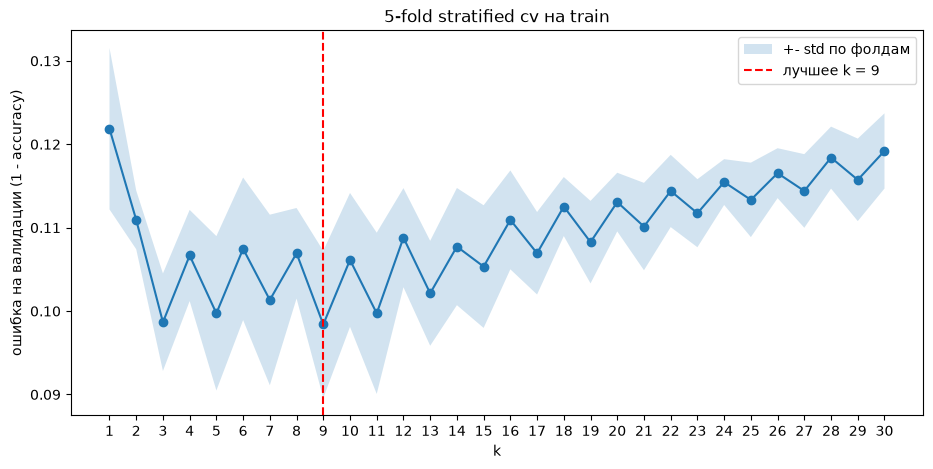

k = 9: точность на test 0.8992


In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(cv_df['k'], cv_df['error'], marker='o')
ax.fill_between(cv_df['k'], cv_df['error'] - cv_df['std_acc'], cv_df['error'] + cv_df['std_acc'], alpha=0.2,
                label='+- std по фолдам')
ax.axvline(best_k, color='red', linestyle='--', label=f'лучшее k = {best_k}')
ax.set(xlabel='k', ylabel='ошибка на валидации (1 - accuracy)', xticks=range(1, 31),
       title='5-fold stratified cv на train')
ax.legend()
plt.show()

# финальная проверка выбранного k на test
knn_best = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
print(f'k = {best_k}: точность на test {knn_best.score(X_test_s, y_test):.4f}')

**Ответ.**

Кросс-валидацию делаю только на train, а скейлер учится заново на каждом обучающем фолде, чтобы валидационный фолд ничего "не подсказывал". StratifiedKFold держит в каждом фолде одинаковую долю ушедших (около 14%).

Что видно на графике:
- при k = 1 ошибка самая большая (0.122): один сосед - это шум, модель переобучается;
- от k = 3 до k = 11 ошибка минимальная, около 0.10;
- дальше ошибка медленно растет: при большом k соседей так много, что голосование все чаще выигрывает большой класс "остался", границы размываются и модель недообучается;
- график пилой: четные k хуже соседних нечетных. При четном k бывает ничья (например, 2 на 2), и sklearn тогда выбирает класс 0, то есть пропускает ушедших. Для бинарной задачи лучше брать нечетное k.

Лучшее k = 9: средняя точность 0.9016 при std 0.0088. Но k = 3, 5, 11 отличаются от него примерно на 0.001, это намного меньше std, так что на практике подходит любое нечетное k от 3 до 11. На отложенном test k = 9 дает 0.8992, почти как на кросс-валидации, значит оценка честная.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [25]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.dummy import DummyClassifier

print('доли классов в test:', y_test.value_counts(normalize=True).round(4).to_dict(), '\n')

# "модель", которая всегда говорит "клиент не уйдет", против нашего knn
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_s, y_train)
rows = []
for name, model in [('всегда "остался"', dummy), (f'knn, k = {best_k}', knn_best)]:
    pred = model.predict(X_test_s)
    rows.append({'модель': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred, zero_division=0),
                 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred)})
pd.DataFrame(rows).round(4)

доли классов в test: {0: 0.8584, 1: 0.1416} 



,модель,accuracy,precision,recall,f1
0,"всегда ""остался""",0.8584,0.00,0.0000,0.0
1,"knn, k = 9",0.8992,0.84,0.3559,0.5


[[1061   12]
 [ 114   63]] 

              precision    recall  f1-score   support

 остался (0)      0.903     0.989     0.944      1073
    ушел (1)      0.840     0.356     0.500       177

    accuracy                          0.899      1250
   macro avg      0.871     0.672     0.722      1250
weighted avg      0.894     0.899     0.881      1250



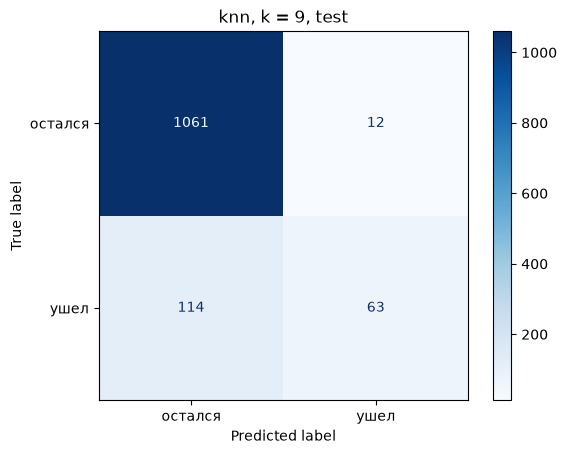

In [26]:
y_pred = knn_best.predict(X_test_s)
print(confusion_matrix(y_test, y_pred), '\n')
print(classification_report(y_test, y_pred, target_names=['остался (0)', 'ушел (1)'], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['остался', 'ушел'], cmap='Blues')
plt.title(f'knn, k = {best_k}, test')
plt.show()

In [27]:
# predict_proba у knn - это доля ушедших среди k соседей. если опустить порог, ловим больше ушедших
proba = knn_best.predict_proba(X_test_s)[:, 1]
rows = []
for thr in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= thr).astype(int)
    rows.append({'порог': thr, 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred)})
pd.DataFrame(rows).round(4)

,порог,accuracy,precision,recall,f1
0,0.5,0.8992,0.8400,0.3559,0.5000
1,0.4,0.9064,0.7542,0.5028,0.6034
2,0.3,0.9064,0.6744,0.6554,0.6648
3,0.2,0.8576,0.4981,0.7571,0.6009


**Ответ.**

В test 85.8% клиентов остались и только 14.2% ушли. Из-за этого accuracy обманывает: "модель", которая всегда отвечает "остался", получает 0.858 и при этом не находит ни одного ушедшего (recall = 0). Наш KNN дает 0.899, и это кажется хорошо, но это всего на 4 пункта лучше, чем ничего не делать.

Матрица ошибок показывает реальную картину: из 177 ушедших модель нашла только 63 (recall 0.356), а 114 пропустила. Зато когда она говорит "уйдет", она права в 84% случаев (precision 0.84). F1 для ушедших 0.50. А для бизнеса важнее всего как раз найти тех, кто собирается уйти, чтобы успеть их удержать. Accuracy этого не видит, потому что в ней доминирует большой класс.

Порог тоже можно двигать. `predict_proba` у KNN - это доля ушедших среди соседей, и по умолчанию нужно больше половины. Если снизить порог до 0.3, recall вырастает с 0.36 до 0.66, F1 с 0.50 до 0.66, и accuracy даже немного растет (0.906). При пороге 0.2 recall 0.76, но precision падает до 0.50, тут уже надо решать, что дороже: пропустить ушедшего или зря предложить скидку тому, кто и так останется.

Вывод: при несбалансированных классах смотрим на матрицу ошибок, precision, recall и F1 по маленькому классу, а не на одну accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [28]:
# шум = клиенты с "чужой" меткой, то есть точки, которые стоят не в своем классе.
# переворачиваем метку у части обучающих клиентов и смотрим точность на чистом test.
# 10 повторов с разным шумом, k = 15. модель - обычный sklearn (StockKNN), из-за бага с distance в упр. 5
def noisy_labels(y_arr, rate, seed):
    rng = np.random.default_rng(seed)
    y_noisy = y_arr.copy()
    idx = rng.choice(len(y_arr), int(rate * len(y_arr)), replace=False)
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy

def noise_experiment(A_train, A_test, k=15, rates=(0, 0.1, 0.2, 0.3), n_seeds=10):
    rows = []
    for rate in rates:
        for weights in ['uniform', 'distance']:
            test_acc, train_acc = [], []
            for seed in range(n_seeds):
                y_noisy = noisy_labels(y_train.to_numpy(), rate, seed)
                knn = StockKNN(n_neighbors=k, weights=weights).fit(A_train, y_noisy)
                test_acc.append(knn.score(A_test, y_test))
                train_acc.append(knn.score(A_train, y_noisy))
            rows.append({'доля шума': rate, 'weights': weights,
                         'test': np.mean(test_acc), 'train (на шумных метках)': np.mean(train_acc)})
    return pd.DataFrame(rows)

# 2 признака из упражнения 4 и все 17 признаков
cols2 = [X.columns.get_loc(c) for c in feat2]
res_2d = noise_experiment(X_train_s[:, cols2], X_test_s[:, cols2])
res_17d = noise_experiment(X_train_s, X_test_s)

pd.concat({'2 признака': res_2d.pivot(index='доля шума', columns='weights'),
           '17 признаков': res_17d.pivot(index='доля шума', columns='weights')}, axis=1).round(4)

2 признака                                          17 признаков  \
                test         train (на шумных метках)                 test   
weights     distance uniform                 distance uniform     distance   
доля шума                                                                    
0.0           0.8808  0.8792                   0.9997  0.8851       0.8992   
0.1           0.8650  0.8762                   0.9997  0.8115       0.8950   
0.2           0.8384  0.8626                   0.9997  0.7372       0.8866   
0.3           0.7699  0.8074                   0.9996  0.6714       0.8406   

                                                    
                  train (на шумных метках)          
weights   uniform                 distance uniform  
доля шума                                           
0.0        0.8992                      1.0  0.9069  
0.1        0.8953                      1.0  0.8287  
0.2        0.8864                      1.0  0.7519  
0.3        0.8404                      1.0  0.6830

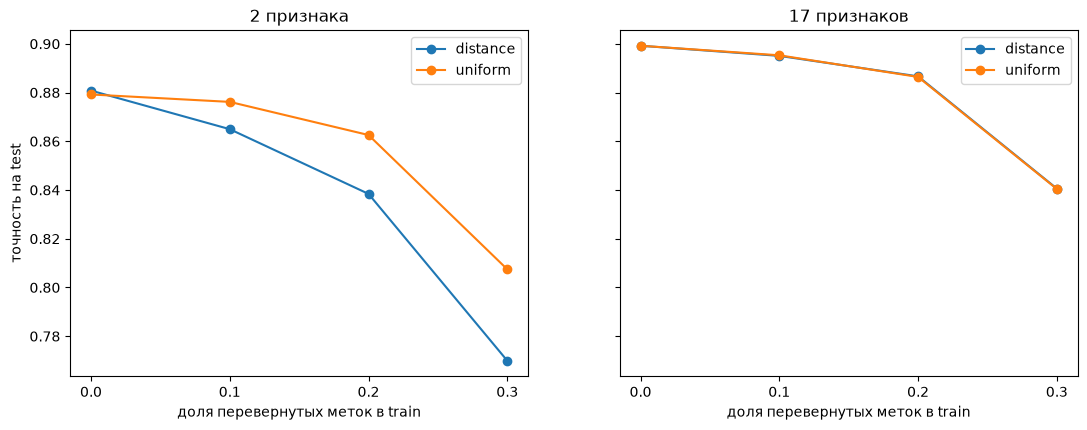

2 признака: 15-й сосед дальше 1-го в 4.58 раза
17 признаков: 15-й сосед дальше 1-го в 1.38 раза


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (title, res) in zip(axes, [('2 признака', res_2d), ('17 признаков', res_17d)]):
    for weights, part in res.groupby('weights'):
        ax.plot(part['доля шума'], part['test'], marker='o', label=weights)
    ax.set(title=title, xlabel='доля перевернутых меток в train', xticks=[0, 0.1, 0.2, 0.3])
    ax.legend()
axes[0].set_ylabel('точность на test')
plt.show()

# во сколько раз 15-й сосед дальше 1-го (медиана по клиентам из test)
for title, A_tr, A_te in [('2 признака', X_train_s[:, cols2], X_test_s[:, cols2]),
                          ('17 признаков', X_train_s, X_test_s)]:
    d, _ = StockKNN(n_neighbors=15).fit(A_tr, y_train).kneighbors(A_te)
    with np.errstate(divide='ignore'):
        print(f'{title}: 15-й сосед дальше 1-го в {np.median(d[:, -1] / d[:, 0]):.2f} раза')

**Ответ.**

Шум в эксперименте - это клиенты с "чужой" меткой: точки, которые оказываются внутри области другого класса, то есть выбросы относительно своего класса. Метки переворачиваю только в train, test остается чистым, k = 15, все усреднено по 10 случайным вариантам шума.

На **2 признаках** без шума оба варианта дают около 0.88. С шумом `distance` падает быстрее:
- 10% шума: 0.865 против 0.876 у `uniform`,
- 20%: 0.838 против 0.863,
- 30%: 0.770 против 0.807.

Еще показательнее точность на самом train с шумными метками: у `distance` она около 1.0 при любом шуме, то есть модель запоминает и неправильные метки тоже. У `uniform` она падает вместе с шумом (0.885 -> 0.671): модель не повторяет шум, а голосует против него.

Почему так: при `distance` вес соседа $1/d$. Если шумная точка лежит совсем рядом с запросом, ее вес намного больше, чем у остальных 14 соседей, и она одна решает ответ. Модель начинает вести себя как K = 1, а K = 1 копирует каждую неправильную метку. При `uniform` у всех 15 соседей по одному голосу: один неправильный сосед ничего не меняет, чтобы ответ испортился, неправильных должно быть 8 из 15. Так что **`weights='distance'` более уязвим к шуму**. У него есть и плюс: дальние соседи, когда точка в редкой области, считаются слабее. Но с грязными метками лучше `uniform` и k побольше.

На **17 признаках** разницы почти нет (при 30% шума 0.8406 и 0.8404). Это уже проклятие размерности (упражнение 10): в 17 измерениях 15-й сосед дальше первого всего в 1.38 раза, а в 2D в 4.58 раза. Расстояния до соседей почти одинаковые, значит и веса $1/d$ почти одинаковые, и `distance` превращается в тот же `uniform`.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

In [30]:
# добавляем к 17 признакам колонки случайного шума из [0, 1] (тот же масштаб, что после MinMaxScaler)
rng = np.random.default_rng(42)
rows = []
for n_noise in [0, 2, 5, 10, 20, 50, 100, 200]:
    A_train = np.hstack([X_train_s, rng.random((len(X_train_s), n_noise))])
    A_test = np.hstack([X_test_s, rng.random((len(X_test_s), n_noise))])
    pred = KNeighborsClassifier(n_neighbors=best_k).fit(A_train, y_train).predict(A_test)
    rows.append({'шумовых колонок': n_noise, 'всего признаков': A_train.shape[1],
                 'accuracy': accuracy_score(y_test, pred), 'recall (ушедшие)': recall_score(y_test, pred),
                 'f1 (ушедшие)': f1_score(y_test, pred)})
dim_df = pd.DataFrame(rows)
dim_df.round(4)

,шумовых колонок,всего признаков,accuracy,recall (ушедшие),f1 (ушедшие)
0,0,17,0.8992,0.3559,0.5000
1,2,19,0.8832,0.2260,0.3540
2,5,22,0.8688,0.1525,0.2477
3,10,27,0.8592,0.0960,0.1619
4,20,37,0.8592,0.0508,0.0928
5,50,67,0.8576,0.0113,0.0220
6,100,117,0.8600,0.0113,0.0223
7,200,217,0.8560,0.0000,0.0000


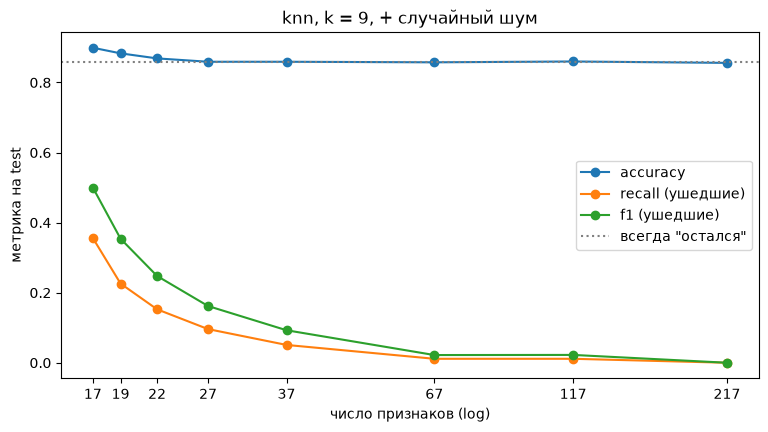

d =    2: самый дальний дальше самого ближнего в 121.85 раза
d =   10: самый дальний дальше самого ближнего в 5.14 раза
d =  100: самый дальний дальше самого ближнего в 1.47 раза
d = 1000: самый дальний дальше самого ближнего в 1.13 раза


In [31]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for col in ['accuracy', 'recall (ушедшие)', 'f1 (ушедшие)']:
    ax.plot(dim_df['всего признаков'], dim_df[col], marker='o', label=col)
ax.axhline(y_test.value_counts(normalize=True).max(), color='gray', linestyle=':', label='всегда "остался"')
ax.set_xscale('log')
ax.set_xticks(dim_df['всего признаков'], dim_df['всего признаков'])
ax.minorticks_off()
ax.set(xlabel='число признаков (log)', ylabel='метрика на test', title=f'knn, k = {best_k}, + случайный шум')
ax.legend()
plt.show()

# почему так: в большой размерности все точки почти на одном расстоянии
for d in [2, 10, 100, 1000]:
    P = rng.random((2000, d))
    dist = np.linalg.norm(P[1:] - P[0], axis=1)
    print(f'd = {d:>4}: самый дальний дальше самого ближнего в {dist.max() / dist.min():.2f} раза')

**Ответ.**

К 17 настоящим признакам добавляю колонки случайного шума из [0, 1], это тот же масштаб, что после MinMaxScaler. Accuracy падает с 0.899 до 0.883 при 2 шумовых колонках, до 0.869 при 5 и примерно до 0.86 при 10 и больше. Это уровень модели "всегда остался" (0.858), то есть модель перестает что-либо находить. По ушедшим это видно еще лучше: F1 0.50 -> 0.35 (2 колонки) -> 0.25 (5) -> 0.16 (10) -> 0.09 (20) -> 0.02 (50) -> 0 (200). Даже 2 лишние колонки уже заметно портят модель.

Почему так:
- каждая шумовая колонка добавляет к $d^2$ случайную величину, в среднем $E(u-v)^2 = 1/6 \approx 0.17$ (для двух равномерных u, v из [0, 1]). Настоящие признаки вместе дают $d^2$ около 0.6 (упражнение 1). Получается, что уже 4-5 шумовых колонок весят столько же, сколько все полезные признаки, и соседи выбираются почти случайно;
- в большой размерности расстояния "слипаются". В последнем эксперименте самая дальняя точка дальше самой ближней в 122 раза при d = 2, в 5.1 раза при d = 10, в 1.47 раза при d = 100 и всего в 1.13 раза при d = 1000. Когда все точки почти на одном расстоянии, слово "ближайший" теряет смысл, а на нем весь KNN и держится;
- объем пространства растет экспоненциально, и чтобы заполнить его так же плотно, данных нужно экспоненциально больше. У нас их всего 3750.

Вывод: для KNN важно не накидывать лишние признаки, а отбирать полезные (поэтому в упражнении 12 стоит SelectKBest).

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

In [32]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

# цель - дневной счет total_day_charge, признаки - минуты и звонки за день
# строки train/test те же, что во всех заданиях
target = 'total_day_charge'
R_train, R_test = df.loc[X_train.index], df.loc[X_test.index]

print('счет / минуты (медиана):', round((df[target] / df['total_day_minutes']).median(), 4))
baseline = mean_squared_error(R_test[target], np.full(len(R_test), R_train[target].mean()))
print('MSE, если всегда предсказывать среднее:', round(baseline, 3))

feature_sets = {'минуты': ['total_day_minutes'],
                'минуты + звонки': ['total_day_minutes', 'total_day_calls']}
rows = []
for k in [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100]:
    row = {'k': k}
    for name, feats in feature_sets.items():
        reg = make_pipeline(MinMaxScaler(), KNeighborsRegressor(n_neighbors=k)).fit(R_train[feats], R_train[target])
        row[f'{name}: MSE train'] = mean_squared_error(R_train[target], reg.predict(R_train[feats]))
        row[f'{name}: MSE test'] = mean_squared_error(R_test[target], reg.predict(R_test[feats]))
    rows.append(row)
reg_df = pd.DataFrame(rows).set_index('k')
reg_df.round(4)

счет / минуты (медиана): 0.17
MSE, если всегда предсказывать среднее: 84.374


,минуты: MSE train,минуты: MSE test,минуты + звонки: MSE train,минуты + звонки: MSE test
k,,,,
1,0.0000,0.0008,0.0044,0.1219
2,0.0001,0.0004,0.0338,0.1174
3,0.0005,0.0008,0.0513,0.1386
5,0.0011,0.0019,0.0703,0.1546
7,0.0026,0.0027,0.1039,0.2184
10,0.0077,0.0066,0.1469,0.2982
15,0.0191,0.0175,0.1947,0.3761
20,0.0314,0.0307,0.2470,0.4380
30,0.0618,0.0641,0.3617,0.5514


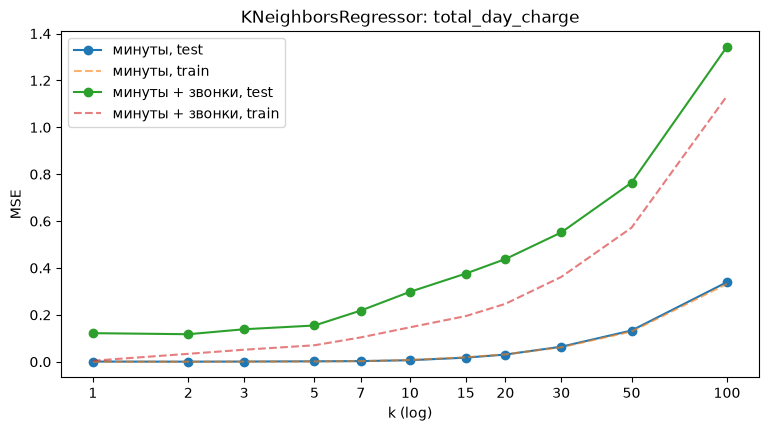

минуты: лучшее k = 2, MSE test = 0.0004
минуты + звонки: лучшее k = 2, MSE test = 0.1174


In [33]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in feature_sets:
    ax.plot(reg_df.index, reg_df[f'{name}: MSE test'], marker='o', label=f'{name}, test')
    ax.plot(reg_df.index, reg_df[f'{name}: MSE train'], linestyle='--', alpha=0.6, label=f'{name}, train')
ax.set_xscale('log')
ax.set_xticks(reg_df.index, reg_df.index)
ax.minorticks_off()
ax.set(xlabel='k (log)', ylabel='MSE', title='KNeighborsRegressor: total_day_charge')
ax.legend()
plt.show()

for name in feature_sets:
    col = f'{name}: MSE test'
    print(f'{name}: лучшее k = {reg_df[col].idxmin()}, MSE test = {reg_df[col].min():.4f}')

**Ответ.**

В регрессии соседи ищутся так же, как в классификации, только вместо голосования берется среднее их значений цели, а качество меряется MSE, а не accuracy.

В этих данных дневной счет - это просто минуты, умноженные на тариф 0.17 (17 центов за минуту), зависимость почти точная. Поэтому KNN по одним минутам предсказывает счет почти идеально: лучшее MSE на test 0.0004 при k = 2, а у константы (всегда среднее) MSE 84.4. k = 2 даже чуть лучше k = 1, потому что среднее соседа слева и соседа справа - это почти линейная интерполяция.

Влияние k: шума в цели нет, поэтому лучше всего маленькие k. С ростом k модель усредняет соседей со все более разными минутами, предсказание "размазывается", и MSE растет: 0.0066 при k = 10, 0.13 при k = 50, 0.34 при k = 100. MSE на train и на test почти одинаковые, значит переобучения нет, а при больших k это смещение (недообучение).

Если добавить звонки, становится хуже: лучшее MSE 0.117 вместо 0.0004, а при k = 100 1.34 вместо 0.34. На счет звонки не влияют, но участвуют в расстоянии, и соседи подбираются наполовину по похожему числу звонков, а не по минутам. Это то же, что в упражнении 10: бесполезный признак портит KNN.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

# knn здесь обычный (StockKNN): при select__k = 5 у сотен клиентов одинаковые признаки,
# расстояние между ними 0, а на этом weights='distance' в sklearnex ошибается (упражнение 5)
pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(score_func=f_classif)),
    ('knn', StockKNN()),
])
param_grid = {
    'select__k': [5, 8, 12, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}
# лучший вариант выбираем по f1: accuracy здесь обманывает (упражнение 8), но ее тоже считаем
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring={'accuracy': 'accuracy', 'f1': 'f1'},
                    refit='f1', n_jobs=-1)
grid.fit(X_train, y_train)   # даем сырые данные, скейлер внутри пайплайна учится на каждом фолде

print('лучшие параметры:', grid.best_params_)
print('f1 на cv:', round(grid.best_score_, 4))
selected = X_train.columns[grid.best_estimator_.named_steps['select'].get_support()]
print('признаки после SelectKBest:', selected.tolist())

cols = ['param_select__k', 'param_knn__n_neighbors', 'param_knn__weights', 'param_knn__p',
        'mean_test_f1', 'mean_test_accuracy']
pd.DataFrame(grid.cv_results_)[cols].sort_values('mean_test_f1', ascending=False).head(10).round(4)

лучшие параметры: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'distance', 'select__k': 8}
f1 на cv: 0.634
признаки после SelectKBest: ['intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_charge', 'total_eve_minutes', 'total_eve_charge', 'number_customer_service_calls']


,param_select__k,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_f1,mean_test_accuracy
37,8,7,distance,1,0.6340,0.9104
2,12,3,uniform,1,0.6317,0.9128
6,12,3,distance,1,0.6310,0.9123
10,12,3,uniform,2,0.6304,0.9128
14,12,3,distance,2,0.6269,0.9117
22,12,5,distance,1,0.6253,0.9160
45,8,7,distance,2,0.6244,0.9080
18,12,5,uniform,1,0.6237,0.9157
53,8,9,distance,1,0.6236,0.9091
33,8,7,uniform,1,0.6195,0.9096


In [35]:
# оценка на test, который до этого ни разу не участвовал в подборе
y_pred_grid = grid.predict(X_test)
print(f'test: accuracy = {accuracy_score(y_test, y_pred_grid):.4f}, f1 = {f1_score(y_test, y_pred_grid):.4f}\n')
print(classification_report(y_test, y_pred_grid, target_names=['остался (0)', 'ушел (1)'], digits=3))

# для сравнения: knn из упражнения 7 (все 17 признаков, k по accuracy)
print(f'knn из упр. 7 (k = {best_k}): accuracy = {accuracy_score(y_test, knn_best.predict(X_test_s)):.4f}, '
      f'f1 = {f1_score(y_test, knn_best.predict(X_test_s)):.4f}')

test: accuracy = 0.9000, f1 = 0.5955

              precision    recall  f1-score   support

 остался (0)      0.924     0.963     0.943      1073
    ушел (1)      0.697     0.520     0.595       177

    accuracy                          0.900      1250
   macro avg      0.810     0.741     0.769      1250
weighted avg      0.892     0.900     0.894      1250

knn из упр. 7 (k = 9): accuracy = 0.8992, f1 = 0.5000


**Ответ.**

Pipeline нужен, чтобы MinMaxScaler и SelectKBest учились только на обучающих фолдах внутри GridSearchCV. Поэтому в `grid.fit` передаются сырые `X_train`, и утечки из валидации нет. Сетка: 4 варианта select__k x 5 значений k x 2 типа весов x 2 метрики = 80 комбинаций, на 5 фолдах это 400 обучений. Лучший вариант выбираю по F1, потому что accuracy здесь обманывает (упражнение 8).

Лучшие параметры: k = 7 соседей, `weights='distance'`, p = 1 (манхэттен) и SelectKBest с k = 8. F1 на кросс-валидации 0.634.

SelectKBest оставил 8 признаков: международный тариф, план голосовой почты и число сообщений, дневные и вечерние минуты и счет, звонки в поддержку. Отброшены стаж, количество звонков днем, вечером и ночью, ночные и международные минуты и счета, которые для оттока в основном шум. После упражнения 10 понятно, почему это помогает KNN. Интересно, что минуты и счет - это одна и та же информация (счет = 0.17 x минуты), так что дневное и вечернее использование учитывается два раза, то есть получает больший вес в расстоянии.

На test: accuracy 0.900 (почти как у простого KNN из упражнения 7, 0.899), но F1 по ушедшим 0.60 вместо 0.50, и recall 0.52 вместо 0.36. То есть модель находит заметно больше уходящих клиентов. В топ-10 у 7 вариантов из 10 p = 1 (манхэттен), и разница между первыми вариантами меньше 0.01 по F1, так что "лучший" набор выбран с точностью до шума кросс-валидации.